# 01 - A Number Is Not Enough

Every regression model outputs a single number. Every decision that consumes it needs
a **range**: a predicted demand of 1,240 is useless for a stocking call without knowing
whether the truth is almost surely 1,200-1,280 or could plausibly be 600 or 1,900.

That range is the **prediction interval**, and there is exactly one metric that judges
it: **coverage** - the fraction of held-out truths the interval actually contains, which
should equal the level it promises (here, 90%). This whole project is a coverage contest.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.artifacts import save_fig, save_json

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NOMINAL = 0.90
SEED = 42

## A single prediction, and the decision it cannot support

We use synthetic data with a **known** error structure (so coverage can be validated
against the truth). The uncertainty grows with `x` - the realistic case.

Point prediction at x=8: 28.2 units  <- but how much should we trust it?


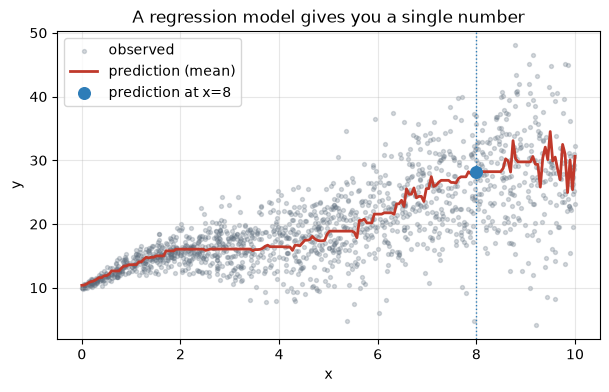

In [2]:
from sklearn.ensemble import GradientBoostingRegressor
from src.datasets.synthetic import make_synthetic

data = make_synthetic("heteroscedastic", 5000, SEED)
x_tr, y_tr = data.x[:3500], data.y[:3500]
x_te, y_te = data.x[3500:], data.y[3500:]

model = GradientBoostingRegressor(random_state=0).fit(x_tr, y_tr)
x0 = 8.0
point = float(model.predict([[x0]])[0])
print(f"Point prediction at x={x0:.0f}: {point:.1f} units  <- but how much should we trust it?")

grid = np.linspace(0, 10, 200).reshape(-1, 1)
fig, ax = plt.subplots()
ax.scatter(x_te, y_te, s=8, alpha=0.25, color="#5B6B7B", label="observed")
ax.plot(grid.ravel(), model.predict(grid), color="#C0392B", lw=2, label="prediction (mean)")
ax.axvline(x0, color="#2E7DB8", ls=":", lw=1)
ax.scatter([x0], [point], color="#2E7DB8", s=70, zorder=5, label=f"prediction at x={x0:.0f}")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper left")
ax.set_title("A regression model gives you a single number")
save_fig(fig, "01_point_prediction")
plt.show()

## The range the decision needs - and the metric that judges it

Attach a 90% interval and immediately **measure** whether it covers.

90% interval at x=8: [20.8, 35.6]
Empirical coverage of this 'textbook' interval: 86.6% (promised 90%)


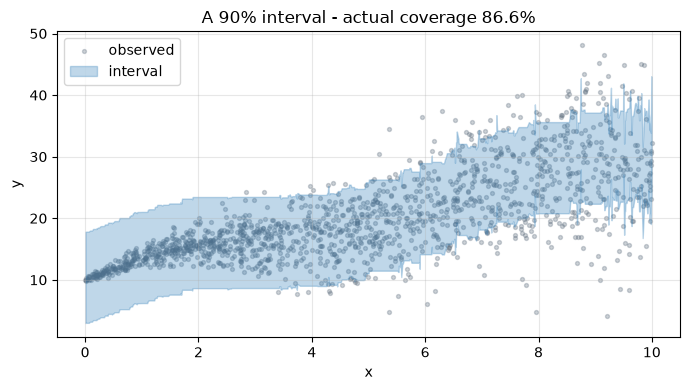

PosixPath('/workspaces/prediction_intervals_arena/outputs/data/01_intro.json')

In [3]:
from src.intervals.normal import NormalInterval
from src.evaluation.coverage import coverage
from src.visualisation import plot_intervals

normal = NormalInterval(coverage=NOMINAL).fit(x_tr, y_tr)
lo, hi = normal.predict_interval(x_te)
cov = coverage(y_te, lo, hi)
lo0, hi0 = normal.predict_interval([[x0]])
print(f"90% interval at x={x0:.0f}: [{lo0[0]:.1f}, {hi0[0]:.1f}]")
print(f"Empirical coverage of this 'textbook' interval: {cov:.1%} (promised {NOMINAL:.0%})")

fig = plot_intervals(x_te, y_te, lo, hi, title=f"A 90% interval - actual coverage {cov:.1%}")
save_fig(fig, "01_first_interval")
plt.show()

save_json("01_intro", {
    "x0": x0,
    "point_prediction": point,
    "interval_at_x0": [float(lo0[0]), float(hi0[0])],
    "nominal_coverage": NOMINAL,
    "empirical_coverage_naive_normal": float(cov),
})

The interval already covers *less* than it promises - and we have not even stressed it
yet. Notebook 02 breaks it properly and shows *where* it fails.